# Causal-Audit quickstart

Use Causal-Audit before choosing a causal discovery method for time series. One call returns diagnostics, risk scores, and either a recommendation or an abstention, with reports and figures.

Run the example below, then replace its data with your own measurements. The [walkthrough](walkthrough.ipynb) explains configuration and interpretation. An audit helps you choose a method; it does not establish causal links.

## Setup

From the repository root, install into your notebook environment:

```bash
python -m pip install -e ".[viz]" ipykernel
python -m ipykernel install --user --name causal-audit --display-name "Python (causal-audit)"
```

Select **Python (causal-audit)**. The import path below identifies the implementation.

Use a numeric `DataFrame` with a chronological, unique `DatetimeIndex`. Keep gaps as `NaN`; filling or deleting them changes the evidence. Several diagnostics need at least 50 observed values per variable.

The example has four variables and 600 daily observations drawn from a VAR(1) with Gaussian innovations.

In [1]:
%matplotlib inline
import json
import warnings
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

import causal_audit
from causal_audit import RiskAwareGatekeeper

# Hide only known tuple-return API deprecation notices; keep audit warnings visible.
warnings.filterwarnings(
    "ignore", message=r"(adfuller|kpss) currently returns a plain tuple",
    category=FutureWarning, module=r"causal_audit\.a_auditor",
)

# Relative output directory so the notebook is portable.
output_dir = Path("examples") / "quickstart_output" if Path("examples").is_dir() else Path("quickstart_output")
print("Installed distribution:", version("causal-audit"))


Installed distribution: 0.3.1


,X0,X1,X2,X3
2020-01-01,-1.316163,-2.014380,-1.559404,0.140185
2020-01-02,-1.394214,-0.158569,-1.238050,-0.367075
2020-01-03,-0.989390,-1.471526,-0.185814,-0.624021
2020-01-04,-1.200550,-0.167038,-0.136321,0.065176
2020-01-05,1.113216,-1.352669,0.420373,-0.476895


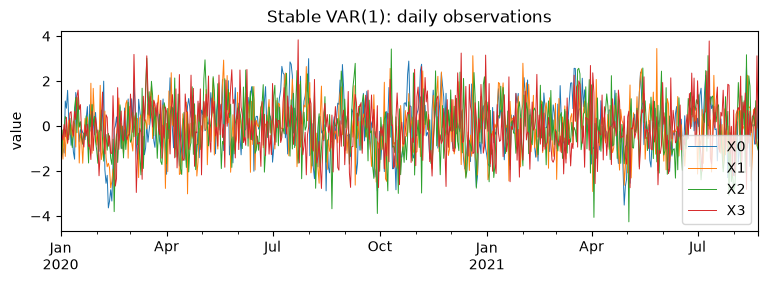

In [2]:
A_clean = np.array([
    [0.5, 0.0, 0.0, 0.0],
    [0.6, 0.0, 0.0, 0.0],
    [0.0, 0.6, 0.0, 0.0],
    [0.0, 0.0, 0.5, 0.0],
])


def simulate_var(A, seed=0, n=600, burn_in=200):
    rng = np.random.default_rng(seed)
    x = np.zeros((n + burn_in, 4))
    for t in range(1, len(x)):
        x[t] = A @ x[t - 1] + rng.normal(size=4)
    return pd.DataFrame(
        x[burn_in:], columns=["X0", "X1", "X2", "X3"],
        index=pd.date_range("2020-01-01", periods=n, freq="D"),
    )


df = simulate_var(A_clean)
display(df.head())
ax = df.plot(figsize=(9, 2.6), linewidth=0.7, title="Stable VAR(1): daily observations")
ax.set_ylabel("value")
display(ax.figure)
plt.close(ax.figure)

## Run the complete audit

This stable VAR has the lagged chain `X0 → X1 → X2 → X3`. Its largest eigenvalue is 0.5, and 200 initial steps are discarded. Those known equations help you interpret the audit.

The call uses the packaged settings and saves six diagnostic figures, tables, and reports. Keep warnings visible.

In [3]:
gatekeeper = RiskAwareGatekeeper(random_seed=42)
result = gatekeeper.analyze(data=df, output_dir=str(output_dir / "clean"))

Phase 1/3: Running assumption audit...


Phase 2/3: Quantifying risks...
Phase 3/3: Generating recommendation...
Generating figures...


  ✓ Generated 6 figures (PDF + PNG, 300 DPI)

✓ Analysis complete! Results saved to quickstart_output/clean
  - Decision: RECOMMEND
  - Recommended method: PCMCI+
  - Confidence: 85.00%


In [4]:
policy = result["policy"]
print("Decision:", policy.decision.upper())
print("Proposed method:", policy.recommended_method or "none — investigate before discovery")
print("Read the explanation:", Path(result["output_dir"]) / "audit_scorecard.md")

Decision: RECOMMEND
Proposed method: PCMCI+
Read the explanation: quickstart_output/clean/audit_scorecard.md


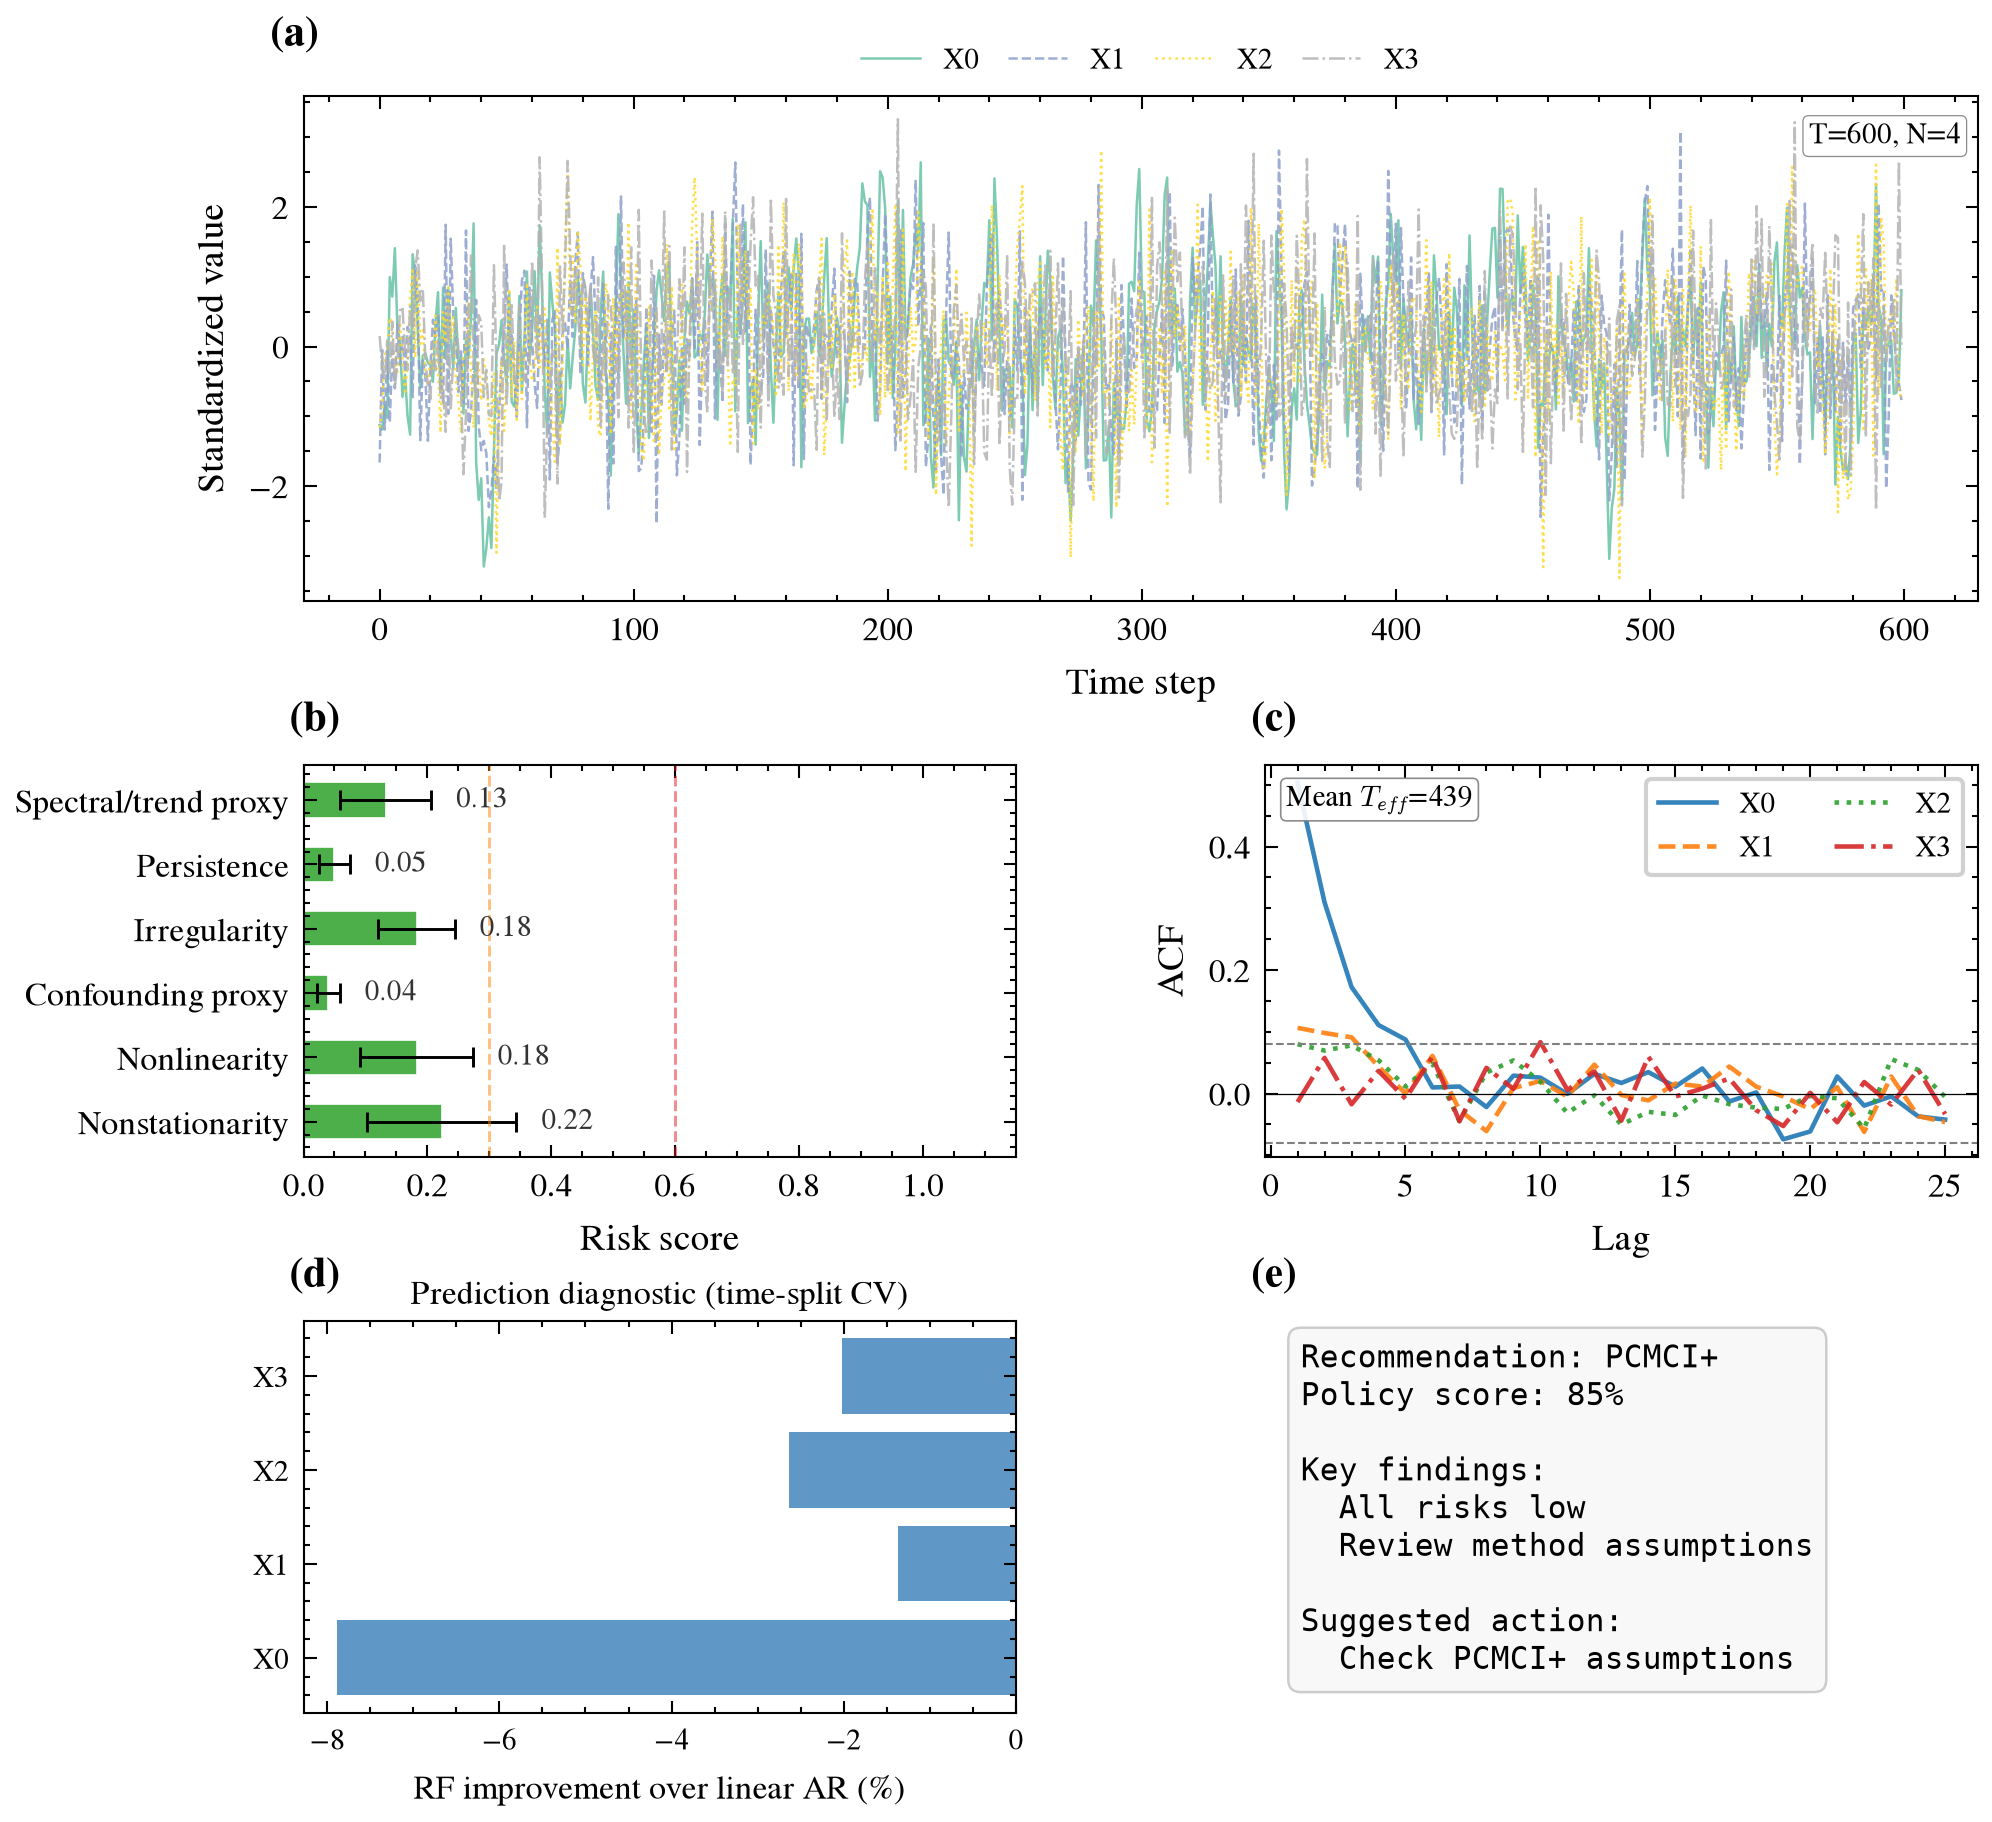

In [5]:
def show_audit_figure(audit_result, figure_name):
    figure_path = Path(audit_result["output_dir"]) / "figures" / f"{figure_name}.png"
    display(Image(filename=str(figure_path), width=950))


show_audit_figure(result, "prediscovery_summary")

## Read the result

The summary shows the series, the risk scores, temporal dependence, the predictive diagnostic, and the policy. Risk bounds are approximate, and policy confidence is not the probability of a correct causal graph.

Read `audit_scorecard.md` for the rationale and the configuration. If the audit abstains, investigate before going further.

For your own data, check timestamps and missing codes, then write to a fresh output folder:

```python
my_data = pd.read_csv("data.csv", parse_dates=["date"], index_col="date").sort_index()
my_result = RiskAwareGatekeeper(random_seed=42).analyze(
    data=my_data, output_dir="results/my_audit",
)
print(my_result["policy"].decision)
```

Keep the input and environment with the reports. The [walkthrough](walkthrough.ipynb) covers the full interpretation.